<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%206/MRayhanZamzami_JS06_Regresi_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 1 - Regresi Linier Sederhana dengan StatsModels

Dataset: Ecommerce Customers (hubungan lama keanggotaan terhadap pengeluaran tahunan).

## Langkah 1 - Import Library dan Baca Data

In [1]:
import numpy as np
import pandas as pd

# Baca dataset
data = pd.read_csv('dataset/Ecommerce Customers.csv')
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [2]:
# Ukuran, informasi, dan statistik deskriptif data
print('Ukuran data:', data.shape)
data.info()
data.describe()

Ukuran data: (500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Langkah 2 - Visualisasi Data

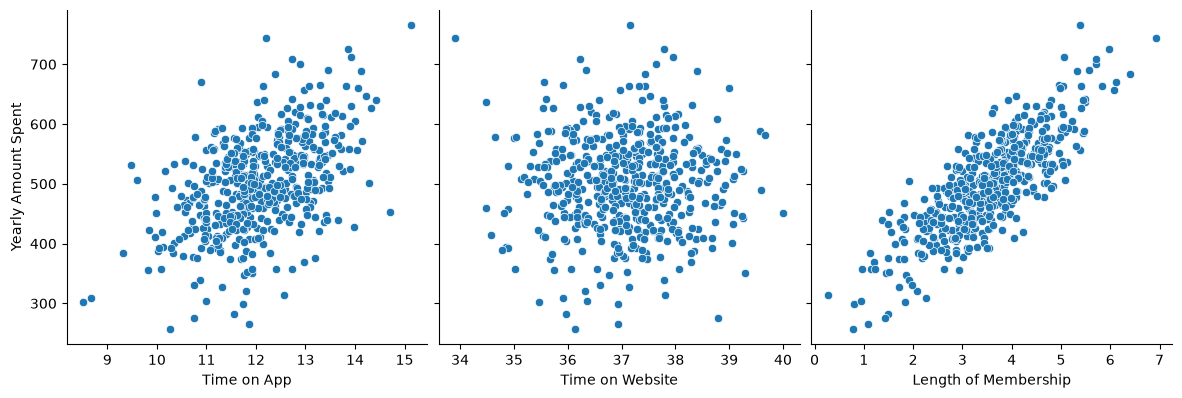

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pairplot fitur numerik terhadap target
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

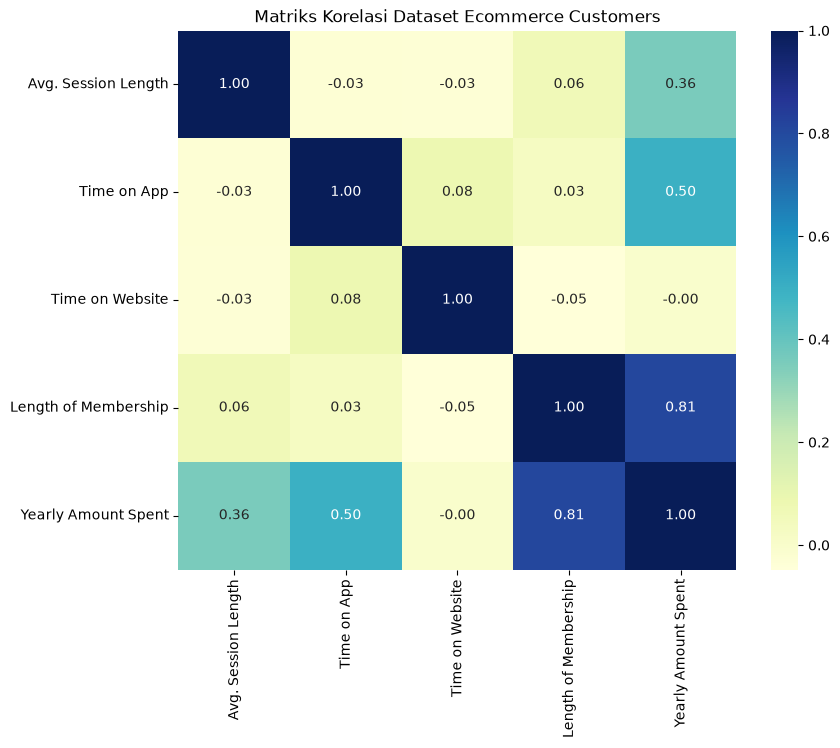

In [4]:
# Heatmap korelasi antar variabel numerik
plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(numeric_only=True), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Matriks Korelasi Dataset Ecommerce Customers')
plt.show()

## Langkah 3 - Regresi Linier Sederhana

In [5]:
# Variabel bebas dan target
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Split data 70% train dan 30% test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

# Training model dengan StatsModels OLS
import statsmodels.api as sm
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         01:53:00   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

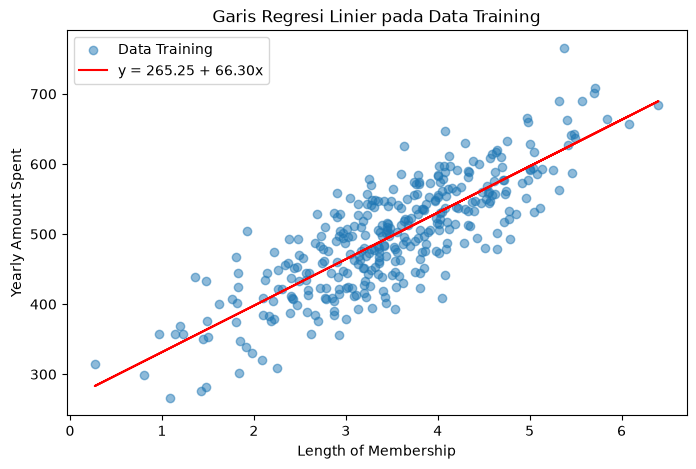

In [6]:
# Visualisasi garis regresi menggunakan parameter hasil training
intercept, slope = lr.params
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.5, label='Data Training')
plt.plot(X_train, intercept + slope * X_train, 'r', label=f'y = {intercept:.2f} + {slope:.2f}x')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Garis Regresi Linier pada Data Training')
plt.legend()
plt.show()

## Langkah 4 - Analisis Residual

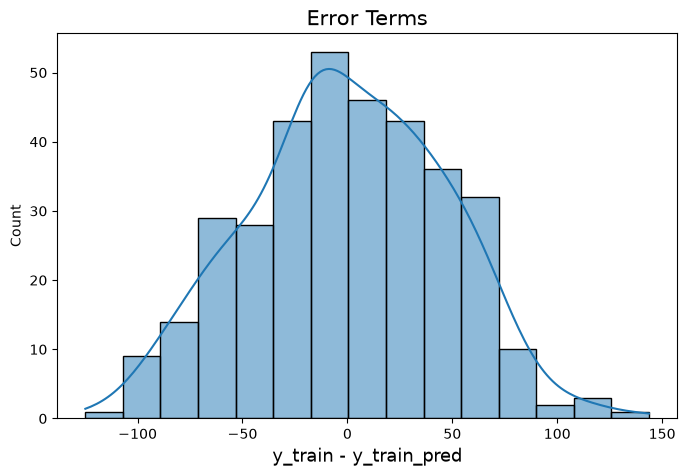

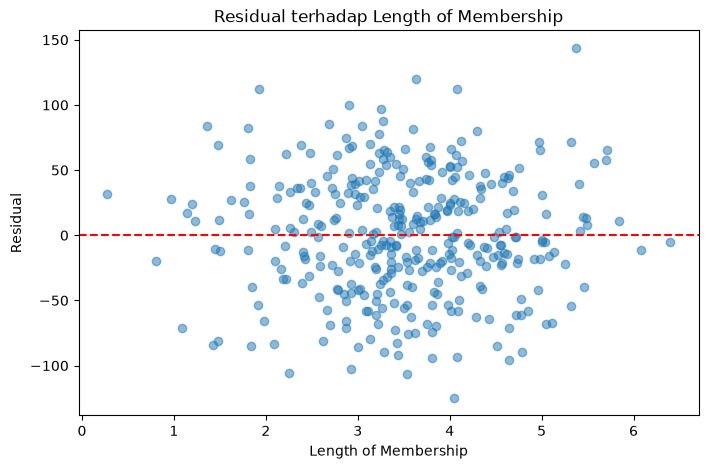

In [7]:
# Prediksi data training dan hitung residual
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred

# Histogram residual
plt.figure(figsize=(8, 5))
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=13)
plt.show()

# Scatter plot residual
plt.figure(figsize=(8, 5))
plt.scatter(X_train, res, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.title('Residual terhadap Length of Membership')
plt.show()

## Langkah 5 - Prediksi Data Uji dan Evaluasi

R-squared : 0.6119
MAE       : 36.8673
MSE       : 2171.3702
RMSE      : 46.5980


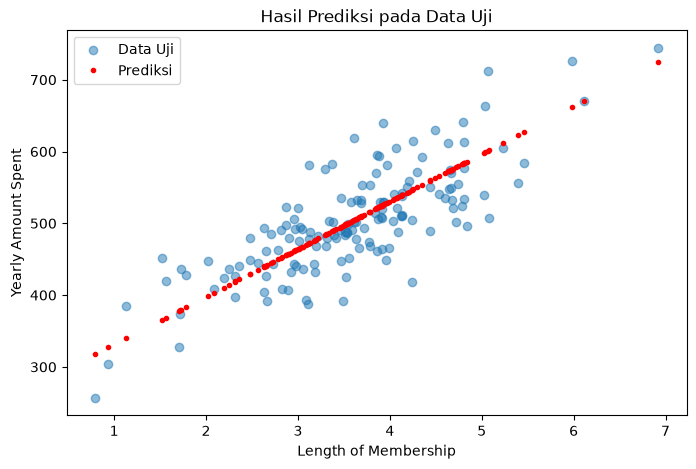

In [8]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Prediksi data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

r_squared = r2_score(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)

print(f'R-squared : {r_squared:.4f}')
print(f'MAE       : {mae:.4f}')
print(f'MSE       : {mse:.4f}')
print(f'RMSE      : {rmse:.4f}')

# Visualisasi data uji dan hasil prediksi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.5, label='Data Uji')
plt.plot(X_test, y_test_pred, 'r.', label='Prediksi')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Hasil Prediksi pada Data Uji')
plt.legend()
plt.show()